# 실습 01 · 이미지·정답 박스

> **Day15 | 객체탐지·YOLO·추적 · 01_기본필수**
> 원본 스크립트: `01_boxes.py` · 교안 PPT 15쪽 · 직접 구현: B01
> 결과: 이 노트북을 실제 실행한 출력

## 학습 목표

- 정답(GT) 박스 표의 xyxy 좌표가 이미지의 어느 위치인지 그려서 확인한다.
- OpenCV 색 순서(BGR)와 좌표 순서(x=열, y=행)를 구분한다.
- GT에는 confidence가 없다는 점을 설명한다.

## 핵심 개념

| 개념 | 설명 |
|---|---|
| xyxy | 왼쪽 위 (x1,y1) ~ 오른쪽 아래 (x2,y2) 픽셀 좌표 |
| shape (H,W,C) | 배열은 (높이, 너비, 채널) 순서 → 160×128 그림은 (128,160,3) |
| BGR | OpenCV 색 순서. (0,255,0)=초록, (0,0,255)=빨강 |
| GT confidence | 정답은 사람이 정한 기록이라 점수가 없음 |

## 0. 준비

- 이 노트북은 `01_기본필수` 폴더(같은 폴더에 `data/`가 있는 위치)에서 연다.
- 입력은 `data/`의 원본을 읽기만 하고, 노트북이 만드는 결과 파일은 `outputs_notebook/`에 저장한다.
- CPU에서 실행한다. GPU·CUDA 코드는 없다.

In [1]:
# ============================================================
# 0. 라이브러리·경로 설정
# ============================================================
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# BASE : 노트북 폴더(01_기본필수) / DATA : 원본 입력 / OUT : 노트북 결과 폴더
BASE = Path.cwd()
DATA = BASE / "data"
OUT = BASE / "outputs_notebook"
OUT.mkdir(exist_ok=True)

def show(images, titles, size=3.2):
    """BGR 배열 여러 장을 한 줄로 표시한다.

    - images: BGR 배열 목록 (OpenCV로 읽은 그대로)
    - titles: 각 그림 제목 목록
    """
    fig, axes = plt.subplots(1, len(images), figsize=(size * len(images), size * 0.9))
    axes = np.atleast_1d(axes)
    for ax, img, title in zip(axes, images, titles):
        # cv2.cvtColor(BGR2RGB) : matplotlib은 RGB 순서로 그리므로 채널 순서를 바꿈
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        ax.set_title(title, fontsize=9)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

## 1. 입력 읽기

이미지와 정답 박스 표를 읽는다. 표에는 `confidence` 열이 없다.

In [2]:
# ============================================================
# 1. 입력 읽기
# ============================================================
image = cv2.imread(str(DATA / "scene.png"))
boxes = pd.read_csv(DATA / "boxes_gt.csv")
print("shape (H, W, C):", image.shape)
print("열 목록:", list(boxes.columns))
boxes

shape (H, W, C): (128, 160, 3)
열 목록: ['image_id', 'class_id', 'x1', 'y1', 'x2', 'y2']


,image_id,class_id,x1,y1,x2,y2
0,scene,0,12,18,52,58
1,scene,1,70,60,108,98
2,scene,2,116,18,150,62


## 2. 정답 박스 그리기 (TODO B01)

`cv2.rectangle(img, pt1, pt2, color, thickness)`에서 앞 4개는 필수, 두께는 선택이다. 원본을 보존하려고 `copy()`한 배열에 그린다.

class: 0 xyxy: 12 18 52 58 GT confidence: N/A
class: 1 xyxy: 70 60 108 98 GT confidence: N/A
class: 2 xyxy: 116 18 150 62 GT confidence: N/A
shape: (128, 160, 3) 저장: outputs_notebook/p01_boxes.png


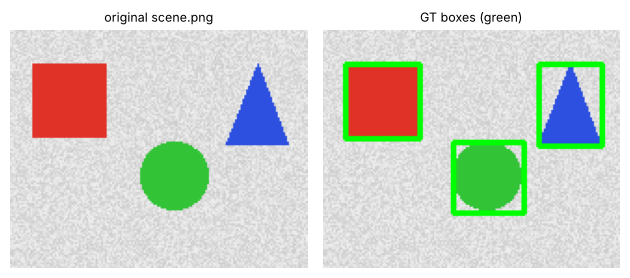

In [3]:
# ============================================================
# 2. 정답 박스 그리기 (TODO B01)
# ============================================================
# result : 그림용 복사본 (image 원본은 그대로)
result = image.copy()
for row in boxes.itertuples():
    # (row.x1, row.y1) : 왼쪽 위, (row.x2, row.y2) : 오른쪽 아래
    # (0, 255, 0) : BGR 초록 / thickness=2 : 선 두께 2px
    cv2.rectangle(result, (row.x1, row.y1), (row.x2, row.y2), (0, 255, 0), thickness=2)
    print("class:", row.class_id, "xyxy:", row.x1, row.y1, row.x2, row.y2, "GT confidence: N/A")
cv2.imwrite(str(OUT / "p01_boxes.png"), result)
print("shape:", image.shape, "저장: outputs_notebook/p01_boxes.png")
show([image, result], ["original scene.png", "GT boxes (green)"])

## 3. 원본 보존 확인

`copy()`를 썼기 때문에 원본 배열은 바뀌지 않았다. 복사 없이 그리면 원본 배열도 같이 바뀐다.

In [4]:
# ============================================================
# 3. 원본 보존 확인
# ============================================================
reread = cv2.imread(str(DATA / "scene.png"))
# np.array_equal : 두 배열의 모양·값이 모두 같으면 True
print("메모리의 원본 배열 그대로:", np.array_equal(image, reread))
print("복사본과 원본이 다른 픽셀 수:", int((result != image).any(axis=2).sum()))

메모리의 원본 배열 그대로: True
복사본과 원본이 다른 픽셀 수: 1392


## 4. BGR 색 순서 실험

같은 숫자 `(0, 0, 255)`를 OpenCV에 주면 빨강, RGB로 해석하면 파랑이다.

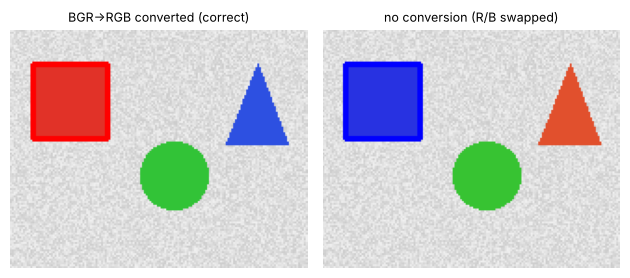

In [5]:
# ============================================================
# 4. BGR 색 순서 실험
# ============================================================
demo = image.copy()
# (0, 0, 255) : OpenCV(BGR)에서는 R=255 -> 빨강
cv2.rectangle(demo, (12, 18), (52, 58), (0, 0, 255), thickness=2)
# 같은 배열을 채널 변환 없이 RGB로 표시하면 빨강·파랑이 뒤바뀌어 보임
fig, axes = plt.subplots(1, 2, figsize=(6.4, 2.9))
axes[0].imshow(cv2.cvtColor(demo, cv2.COLOR_BGR2RGB)); axes[0].set_title("BGR->RGB converted (correct)", fontsize=9)
axes[1].imshow(demo); axes[1].set_title("no conversion (R/B swapped)", fontsize=9)
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

## 정리 (README 설명 질문)

- **GT에도 confidence가 있는가?** 없다. `boxes_gt.csv`의 열은 image_id·class_id·x1·y1·x2·y2뿐이다. confidence는 모델 예측에만 있다.
- **BGR 순서와 xyxy 의미:** OpenCV 색은 (B, G, R) 순서라 `(0,255,0)`이 초록이다. xyxy는 x=가로(열), y=세로(행)이며 배열 접근 `image[y, x]`와 순서가 반대다.